In [1]:
## Importing packages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline


### Importing data

In [2]:
df = pd.read_parquet("fraud_features_cleaned.parquet",engine="fastparquet")

In [3]:
df.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Is_Fraud,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,29.238259,1,1771,0,30.985221,1,1,2,27.647835,0,0,0,1,0,0,0.005464,0.0,2.0
1,717.843218,0,1487,0,17.942120,1,0,3,797.821172,0,0,0,0,0,1,0.016373,0.0,2.0
2,572.436291,4,1736,0,41.518005,1,2,5,519.277405,0,0,0,0,1,0,0.012047,0.0,2.0
3,19.882388,3,242,0,1.096487,1,0,2,21.100069,0,0,0,0,0,1,0.016563,0.0,2.0
4,109.195865,3,1060,1,32.611307,1,0,2,128.525243,0,0,0,1,0,0,0.010643,0.0,2.0


### EDA

In [4]:
df.dtypes

Transaction_Amount_USD       float64
Merchant_Category              int64
Account_Age_Days               int64
Failed_Login_Attempts          int64
Distance_From_Home_Miles     float64
IP_Country_Match               int64
Transaction_Velocity_1hr       int64
Transaction_Velocity_24hr      int64
Avg_Amount_24hr_USD          float64
Is_Weekend                     int64
Is_Fraud                       int64
Android                        int64
Linux                          int64
Windows                        int64
iOS                            int64
Merchant_ID_TE               float64
Hour                         float64
Day_of_Week                  float64
dtype: object

In [5]:
df.isnull().sum()

Transaction_Amount_USD           0
Merchant_Category                0
Account_Age_Days                 0
Failed_Login_Attempts            0
Distance_From_Home_Miles         0
IP_Country_Match                 0
Transaction_Velocity_1hr         0
Transaction_Velocity_24hr        0
Avg_Amount_24hr_USD              0
Is_Weekend                       0
Is_Fraud                         0
Android                          0
Linux                            0
Windows                          0
iOS                              0
Merchant_ID_TE                   0
Hour                         50000
Day_of_Week                  50000
dtype: int64

In [6]:
df.columns

Index(['Transaction_Amount_USD', 'Merchant_Category', 'Account_Age_Days',
       'Failed_Login_Attempts', 'Distance_From_Home_Miles', 'IP_Country_Match',
       'Transaction_Velocity_1hr', 'Transaction_Velocity_24hr',
       'Avg_Amount_24hr_USD', 'Is_Weekend', 'Is_Fraud', 'Android', 'Linux',
       'Windows', 'iOS', 'Merchant_ID_TE', 'Hour', 'Day_of_Week'],
      dtype='str')

In [7]:
df.shape

(500000, 18)

In [8]:
df.describe()

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Is_Fraud,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
count,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.00000,500000.000000,500000.000000,450000.000000,450000.000000
mean,488.634138,2.152050,898.871902,0.230396,14.894328,0.899952,1.054702,3.110570,481.251277,0.285018,0.011972,0.400650,0.050368,0.09991,0.449072,0.011972,11.491038,2.992920
std,1220.270661,1.108838,519.897860,0.675827,14.871308,0.300064,0.977887,1.967153,965.915270,0.451423,0.108760,0.490031,0.218703,0.29988,0.497400,0.004700,6.924244,1.995414
min,5.000484,0.000000,0.000000,0.000000,0.000053,0.000000,0.000000,0.000000,4.015665,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000203,0.000000,0.000000
25%,25.424785,2.000000,448.000000,0.000000,4.401824,1.000000,0.000000,2.000000,25.162453,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.008827,5.000000,1.000000
50%,60.180208,2.000000,899.000000,0.000000,10.385838,1.000000,1.000000,3.000000,59.891629,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.011788,11.000000,3.000000
75%,261.894909,3.000000,1349.000000,0.000000,20.442562,1.000000,2.000000,4.000000,261.428903,1.000000,0.000000,1.000000,0.000000,0.00000,1.000000,0.014790,17.000000,5.000000
max,99113.203087,4.000000,1799.000000,5.000000,200.316610,1.000000,9.000000,20.000000,5990.378118,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,0.028632,23.000000,6.000000


In [9]:
df['Merchant_Category'].isnull().sum()

np.int64(0)

In [10]:
df.isnull().sum()

Transaction_Amount_USD           0
Merchant_Category                0
Account_Age_Days                 0
Failed_Login_Attempts            0
Distance_From_Home_Miles         0
IP_Country_Match                 0
Transaction_Velocity_1hr         0
Transaction_Velocity_24hr        0
Avg_Amount_24hr_USD              0
Is_Weekend                       0
Is_Fraud                         0
Android                          0
Linux                            0
Windows                          0
iOS                              0
Merchant_ID_TE                   0
Hour                         50000
Day_of_Week                  50000
dtype: int64

### Splitting the data in train and test

In [11]:
n = len(df)
n_test = int(n*0.2)
n_train = int(n - n_test)

In [12]:
print((n,n_test, n_train))

(500000, 100000, 400000)


In [13]:
# distributing train, test and validation datasets.
df_test = df.iloc[ : int(n_test)]
df_train = df.iloc[int(n_test) : ]

In [14]:
df_test['Hour'].isnull().sum()

np.int64(0)

In [15]:
print(f'Shape of training dataset:{df_train.shape}')
print(f'Shape of test dataset:{df_test.shape}')

Shape of training dataset:(400000, 18)
Shape of test dataset:(100000, 18)


In [16]:
# Droppping the old indixes which are saved as column.
df_test = df_test.reset_index(drop = True)
df_train = df_train.reset_index(drop =True)

In [17]:
df_test.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Is_Fraud,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,29.238259,1,1771,0,30.985221,1,1,2,27.647835,0,0,0,1,0,0,0.005464,0.0,2.0
1,717.843218,0,1487,0,17.942120,1,0,3,797.821172,0,0,0,0,0,1,0.016373,0.0,2.0
2,572.436291,4,1736,0,41.518005,1,2,5,519.277405,0,0,0,0,1,0,0.012047,0.0,2.0
3,19.882388,3,242,0,1.096487,1,0,2,21.100069,0,0,0,0,0,1,0.016563,0.0,2.0
4,109.195865,3,1060,1,32.611307,1,0,2,128.525243,0,0,0,1,0,0,0.010643,0.0,2.0


### splliting the data x, y 

In [18]:
y_train = df_train['Is_Fraud']
y_test = df_test['Is_Fraud']

In [19]:
X_train = df_train.drop(columns=['Is_Fraud'])
X_test = df_test.drop(columns=['Is_Fraud'])

In [20]:
X_train

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,58.204133,2,1486,0,12.345333,1,1,2,59.323300,0,1,0,0,0,0.028632,NaN,NaN
1,95.663186,3,962,0,12.127783,1,1,1,76.740279,0,0,0,0,1,0.017358,NaN,NaN
2,8.266796,2,1652,0,1.307577,1,0,1,7.776989,0,0,0,0,1,0.012447,NaN,NaN
3,16.124125,2,1567,0,10.940974,1,1,1,17.606635,0,0,1,0,0,0.007304,NaN,NaN
4,157.793924,2,1737,0,9.322771,1,1,4,135.264274,0,0,0,0,1,0.012669,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,6.217553,3,1401,0,0.865180,1,0,3,6.206533,0,1,0,0,0,0.008533,23.0,2.0
399996,39.252568,3,976,0,3.700393,1,1,2,34.921098,0,0,0,0,1,0.010515,23.0,2.0
399997,15.572066,2,1200,0,15.044283,1,2,4,18.540503,0,1,0,0,0,0.010851,23.0,2.0
399998,96.120914,2,1183,1,6.146887,1,0,2,95.674461,0,0,0,0,1,0.008393,23.0,2.0


In [21]:
print(f'Shape of X_train, y_train: {(X_train.shape, y_train.shape)}')
print(f'Shape of X_test, y_test: {(X_test.shape, y_test.shape)}')

Shape of X_train, y_train: ((400000, 17), (400000,))
Shape of X_test, y_test: ((100000, 17), (100000,))


In [22]:
X_train.head(10)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,58.204133,2,1486,0,12.345333,1,1,2,59.323300,0,1,0,0,0,0.028632,NaN,NaN
1,95.663186,3,962,0,12.127783,1,1,1,76.740279,0,0,0,0,1,0.017358,NaN,NaN
2,8.266796,2,1652,0,1.307577,1,0,1,7.776989,0,0,0,0,1,0.012447,NaN,NaN
3,16.124125,2,1567,0,10.940974,1,1,1,17.606635,0,0,1,0,0,0.007304,NaN,NaN
4,157.793924,2,1737,0,9.322771,1,1,4,135.264274,0,0,0,0,1,0.012669,NaN,NaN
5,390.201007,4,439,0,2.432670,1,2,5,347.081637,0,0,0,0,1,0.003655,NaN,NaN
6,12.576124,3,250,0,43.585686,1,0,3,12.650998,0,0,0,1,0,0.015049,NaN,NaN
7,31.729550,2,514,0,10.514360,1,2,3,28.164611,0,0,0,0,1,0.010461,NaN,NaN
8,46.544704,2,479,0,4.490672,1,1,4,41.117994,0,0,1,0,0,0.028632,NaN,NaN
9,38.305968,2,266,0,2.426142,1,1,5,37.251434,0,1,0,0,0,0.012170,NaN,NaN


In [23]:
X_train['Hour']

0          NaN
1          NaN
2          NaN
3          NaN
4          NaN
          ... 
399995    23.0
399996    23.0
399997    23.0
399998    23.0
399999    23.0
Name: Hour, Length: 400000, dtype: float64

### Filling the NaN value with 0

In [24]:
print(X_train['Hour'].dtypes)
print(X_train['Hour'].isnull().sum())

float64
50000


In [25]:
X_train['Hour'] = X_train['Hour'].fillna(0)
X_test['Hour'] = X_test['Hour'].fillna(0)

In [26]:
X_train['Day_of_Week'] = X_train['Day_of_Week'].fillna(0)
X_test['Day_of_Week'] = X_test['Day_of_Week'].fillna(0)

In [27]:
X_train.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,58.204133,2,1486,0,12.345333,1,1,2,59.323300,0,1,0,0,0,0.028632,0.0,0.0
1,95.663186,3,962,0,12.127783,1,1,1,76.740279,0,0,0,0,1,0.017358,0.0,0.0
2,8.266796,2,1652,0,1.307577,1,0,1,7.776989,0,0,0,0,1,0.012447,0.0,0.0
3,16.124125,2,1567,0,10.940974,1,1,1,17.606635,0,0,1,0,0,0.007304,0.0,0.0
4,157.793924,2,1737,0,9.322771,1,1,4,135.264274,0,0,0,0,1,0.012669,0.0,0.0


### analysis of continious variable

In [28]:
X_train.nunique().sort_values()

IP_Country_Match                  2
Linux                             2
Android                           2
iOS                               2
Windows                           2
Is_Weekend                        2
Failed_Login_Attempts             4
Merchant_Category                 5
Day_of_Week                       7
Transaction_Velocity_1hr         10
Transaction_Velocity_24hr        21
Hour                             24
Merchant_ID_TE                  576
Account_Age_Days               1800
Distance_From_Home_Miles     400000
Transaction_Amount_USD       400000
Avg_Amount_24hr_USD          400000
dtype: int64

In [29]:
X_train['Transaction_Velocity_1hr'].value_counts()

Transaction_Velocity_1hr
2    131812
1    131809
0    131805
5       814
4       810
7       801
6       774
8       561
3       477
9       337
Name: count, dtype: int64

In [30]:
X_train['Transaction_Velocity_24hr'].value_counts()

Transaction_Velocity_24hr
3     79552
2     79172
4     78778
1     52795
5     52018
6     26533
0     26472
13      510
14      506
12      502
11      476
15      435
10      427
16      411
9       354
17      295
8       240
18      190
7       188
19      111
20       35
Name: count, dtype: int64

### Applying StanderdScaling

In [31]:
continious_variable = ['Avg_Amount_24hr_USD','Transaction_Amount_USD','Distance_From_Home_Miles','Account_Age_Days','Merchant_ID_TE']

In [32]:
from sklearn.preprocessing import StandardScaler

In [33]:
scaler = StandardScaler()

In [34]:
X_train[continious_variable] = scaler.fit_transform(X_train[continious_variable])
X_test[continious_variable] = scaler.fit_transform(X_test[continious_variable])

In [35]:
print(f'Shape of X_train: {(X_train.shape)}')
print(f'Shape of X_test: {(X_test.shape)}')

Shape of X_train: (400000, 17)
Shape of X_test: (100000, 17)


In [36]:
X_train.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,-0.338588,2,1.129096,0,-0.175351,1,1,2,-0.436935,0,1,0,0,0,3.546253,0.0,0.0
1,-0.309267,3,0.121457,0,-0.189849,1,1,1,-0.418913,0,0,0,0,1,1.147057,0.0,0.0
2,-0.377677,2,1.448310,0,-0.910909,1,0,1,-0.490272,0,0,0,0,1,0.101952,0.0,0.0
3,-0.371527,2,1.284857,0,-0.268938,1,1,1,-0.480101,0,0,1,0,0,-0.992450,0.0,0.0
4,-0.260634,2,1.611763,0,-0.376775,1,1,4,-0.358356,0,0,0,0,1,0.149085,0.0,0.0


#### Traing the model on LR

In [37]:
# Logistic regression using scikit-learn
from sklearn.linear_model import LogisticRegression

In [38]:
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [39]:
model.intercept_[0]

np.float64(-26.032788622685484)

In [40]:
model.coef_[0].round(3)

array([-0.416, -0.241, -0.276,  0.422,  0.133, -1.272,  3.746,  3.438,
        0.185, -0.19 , -6.926, -5.368, -6.86 , -6.25 ,  0.524, -0.029,
        0.007])

In [41]:
model.predict(X_test)

array([0, 0, 0, ..., 0, 0, 0], shape=(100000,))

In [42]:
y_pred = model.predict_proba(X_test)[:,1]

In [43]:
y_pred[:10]

array([8.32913163e-11, 9.63904543e-11, 2.35505637e-05, 2.97026694e-12,
       4.81795487e-12, 1.32288319e-11, 1.38324073e-09, 1.00750917e-03,
       5.23537744e-09, 5.50285447e-09])

In [44]:
y_prediction  = (y_pred >= 0.5).astype(int)

In [45]:
from sklearn.metrics import confusion_matrix

In [46]:
confusion_matrix(y_test, y_prediction)

array([[98807,     0],
       [   16,  1177]])

### MOdel Evaluation

In [47]:
df_pred = pd.DataFrame()
df_pred['Probability'] = y_pred
df_pred['y_prediction'] = y_prediction
df_pred['Actual_Value'] = y_test
df_pred['Correct'] = (y_prediction == y_test)



In [48]:
df_pred.head()

,Probability,y_prediction,Actual_Value,Correct
0,8.329132e-11,0,0,True
1,9.639045e-11,0,0,True
2,2.355056e-05,0,0,True
3,2.970267e-12,0,0,True
4,4.817955e-12,0,0,True


In [49]:
df_pred['Correct'].value_counts()

Correct
True     99984
False       16
Name: count, dtype: int64

In [50]:
Correct_prediction = 99984
Wrong_prediction = 16
Total = Correct_prediction + Wrong_prediction

In [51]:
accuracy = (Correct_prediction/ Total)*100

In [52]:
print(f'Accuracy of the model is : {accuracy} %')

Accuracy of the model is : 99.984 %


In [53]:
TN, FP, FN, TP = confusion_matrix(y_test, y_prediction).ravel()

In [54]:
print(f' True Positive :{TP}')
print(f' True Negative :{TN}')
print(f' False Positive :{FP}')
print(f' False Negative :{FN}')


 True Positive :1177
 True Negative :98807
 False Positive :0
 False Negative :16


In [55]:
precision = TP/(TP+FP)
Recall = TP/(TP+FN)

In [56]:
print(f' Precision :{precision}')
print(f' Recall :{Recall}')

 Precision :1.0
 Recall :0.9865884325230512


In [57]:
!pip install imbalanced-learn

### Applying smot for oversampling.

In [58]:
from imblearn.over_sampling import SMOTE

In [59]:
smote = SMOTE(random_state=42)

In [60]:
X_train_smoted,y_train_smoted = smote.fit_resample(X_train,y_train)

In [61]:
le = LogisticRegression()
le.fit(X_train_smoted, y_train_smoted)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [62]:
X_train_smoted.describe()

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
count,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000,790414.000000
mean,0.077104,1.948767,-0.041279,0.211914,-0.019463,0.874318,3.165902,7.677784,0.105997,0.253538,0.305749,0.064826,0.059886,0.354920,0.188148,10.090091,2.603438
std,0.976536,1.130040,0.972112,0.681115,0.944212,0.331491,2.575533,5.319376,1.139158,0.435036,0.460724,0.246218,0.237276,0.478489,0.951016,7.536183,2.092926
min,-0.380234,0.000000,-1.728445,0.000000,-0.998042,0.000000,0.000000,0.000000,-0.494164,0.000000,0.000000,0.000000,0.000000,0.000000,-2.503741,0.000000,0.000000
25%,-0.361045,1.000000,-0.874644,0.000000,-0.682268,1.000000,1.000000,3.000000,-0.468004,0.000000,0.000000,0.000000,0.000000,0.000000,-0.439568,3.000000,0.566907
50%,-0.332412,2.000000,-0.043919,0.000000,-0.306423,1.000000,2.000000,6.000000,-0.430365,0.000000,0.000000,0.000000,0.000000,0.000000,0.139525,10.000000,2.306151
75%,0.025426,2.000000,0.786676,0.000000,0.335970,1.000000,5.000000,12.000000,0.036422,1.000000,1.000000,0.000000,0.000000,1.000000,0.765034,17.000000,4.340287
max,77.197453,4.000000,1.730987,5.000000,12.351078,1.000000,9.000000,20.000000,5.700154,1.000000,1.000000,1.000000,1.000000,1.000000,3.546253,23.000000,6.000000


In [63]:
y_pred_smote = le.predict_proba(X_test)[:,1]

In [64]:
y_pred_smote

array([1.04214540e-12, 8.72843439e-14, 2.56615984e-04, ...,
       3.20911434e-03, 6.56829436e-09, 1.65670658e-14], shape=(100000,))

In [65]:
y_prediction_smote  = (y_pred >= 0.5).astype(int)

In [66]:
y_prediction_smote[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [67]:
X, X_, y, y_ = confusion_matrix(y_test, y_prediction_smote).ravel()

In [68]:
print(f' True Positive :{X}')
print(f' True Negative :{X_}')
print(f' False Positive :{y}')
print(f' False Negative :{y_}')


 True Positive :98807
 True Negative :0
 False Positive :16
 False Negative :1177


In [69]:
precision_smote = X/(X+y)
Recall_smote = X/(X+y_)

In [70]:
print(f'Smoted Precision :{precision_smote}')
print(f' Smoted Recall :{Recall_smote}')

Smoted Precision :0.9998380943707437
 Smoted Recall :0.9882281164986397


### APPLYING Random ForesT Classifier

In [71]:
from sklearn.ensemble import RandomForestClassifier

In [72]:
rf_model = RandomForestClassifier(n_estimators=100, random_state = 42)

In [73]:
rf_model.fit(X_train_smoted, y_train_smoted)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [74]:
y_pred_rf = rf_model.predict(X_test)

In [75]:
y_prob_rf = rf_model.predict_proba(X_test)[:,1]   

In [76]:
y_prob_rf[:10]

array([0.  , 0.  , 0.01, 0.  , 0.  , 0.  , 0.  , 0.01, 0.  , 0.01])

In [77]:
y_prediction_rf  = (y_prob_rf >= 0.5).astype(int)

In [78]:
y_prediction_rf[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

#### Model Evaluation

In [79]:
from sklearn.metrics import f1_score

In [80]:
print(f'F1-Score of Random Forest Classifier: {f1_score(y_test,y_prediction_rf)}')

F1-Score of Random Forest Classifier: 0.998320738874895


In [81]:
print(f'F1-Score of Logistic Regression: {f1_score(y_test,y_prediction_smote)}')

F1-Score of Logistic Regression: 0.9932489451476794


In [82]:
TP_rf, TN_rf, FP_rf, FN_rf = confusion_matrix(y_test,y_prediction_rf).ravel()

In [83]:
print(f' True Positive :{TP_rf}')
print(f' True Negative :{TN_rf}')
print(f' False Positive :{FP_rf}')
print(f' False Negative :{FN_rf}')

 True Positive :98807
 True Negative :0
 False Positive :4
 False Negative :1189


In [84]:
precision_rf = TP_rf/(TP_rf+FP_rf)
Recall_rf = TP_rf/(TP_rf+FN_rf)

In [85]:
print(f'Random Forest Precision :{precision_rf}')
print(f' Random Forest Recall :{Recall_rf}')

Random Forest Precision :0.9999595186770703
 Random Forest Recall :0.9881095243809752


#### ROC AND AUC curve

In [86]:
from sklearn.metrics import roc_curve, roc_auc_score

In [87]:
fpr_lr,tpr_lr,_ = roc_curve(y_test,y_pred_smote)
fpr_rf,tpr_rf,_= roc_curve(y_test,y_prediction_rf)

In [88]:
auc_lr = roc_auc_score(y_test,y_pred_smote)
auc_rf = roc_auc_score(y_test,y_prediction_rf)

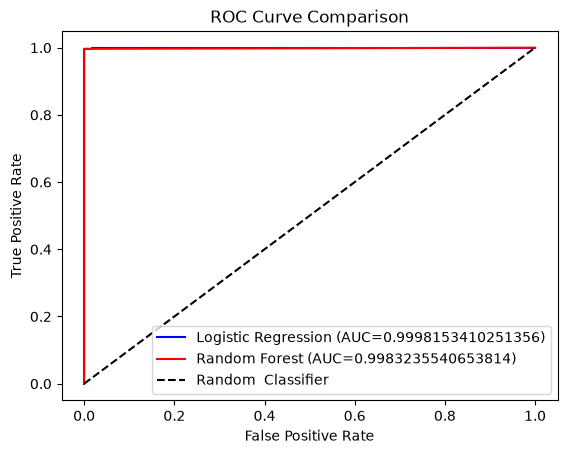

In [89]:
plt.plot(fpr_lr,tpr_lr,color='blue',label=f'Logistic Regression (AUC={auc_lr})')
plt.plot(fpr_rf,tpr_rf,color='red',label=f'Random Forest (AUC={auc_rf})')
plt.plot([0, 1],[0, 1],'k--',label='Random  Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.show()

#### Precision and Recall Graph

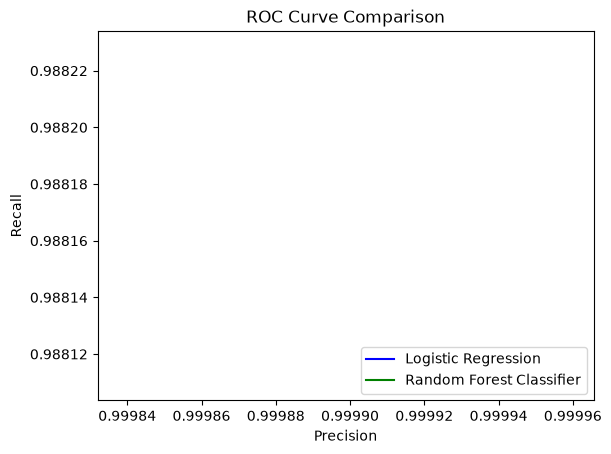

In [90]:
plt.plot(precision_smote,Recall_smote,color='blue',label=f'Logistic Regression ')
plt.plot(precision_rf,Recall_rf,color='green',label=f'Random Forest Classifier')
plt.xlabel('Precision')
plt.ylabel('Recall')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.show()

### Top 10 Feature selection of Random Forest

In [91]:
important_feature = pd.DataFrame({'features':X_train.columns, 'importance':rf_model.feature_importances_})

In [92]:
top_10 = important_feature.sort_values(by='importance',ascending=False).head(10)

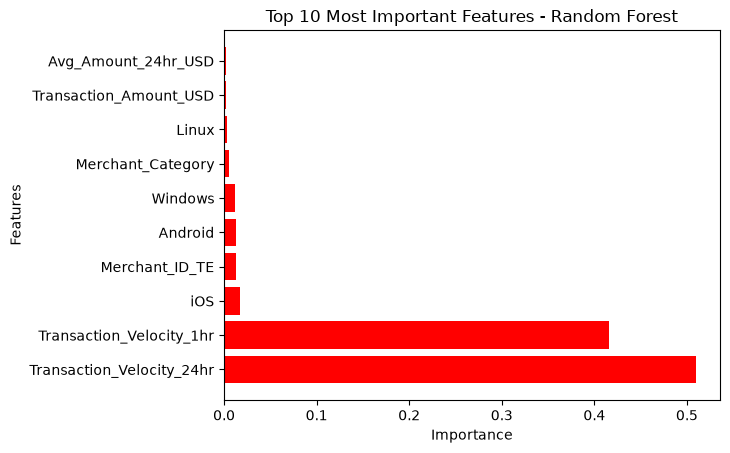

In [93]:
plt.barh(top_10['features'],top_10['importance'], color = 'red')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Top 10 Most Important Features - Random Forest')
plt.show()

### Saving the Metrices in file.

In [94]:
with open("baseline_results.txt", "w") as f:
    f.write("Baseline Model Results\n")
    f.write("=" * 40 + "\n\n")
    f.write(f"Accuracy : {accuracy:.4f}\n")
    f.write(f"Precision of Logistic Regression: {precision_smote:.4f}\n")
    f.write(f"Recall of Logistic Regression   : {Recall_smote:.4f}\n")
    f.write(f"Precision of Random Forest Classifier: {precision_rf:.4f}\n")
    f.write(f"Recall of Random Forest Classifier   : {Recall_rf:.4f}\n")
    f.write(f"F1 Score of Logistic Regression : {f1_score(y_test,y_prediction_smote):.4f}\n")
    f.write(f"F1 Score of Ramdom Forest : {f1_score(y_test,y_prediction_rf):.4f}\n")


In [95]:
X_test.head()

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,-0.470893,1,1.678929,0,1.147047,1,1,2,-0.469208,0,0,1,0,0,-1.387447,0.0,2.0
1,0.248274,0,1.132120,0,0.235909,1,0,3,0.329846,0,0,0,0,1,0.932183,0.0,2.0
2,0.096413,4,1.611541,0,1.882825,1,2,5,0.040857,0,0,0,1,0,0.012348,0.0,2.0
3,-0.480664,3,-1.264987,0,-0.940858,1,0,2,-0.476002,0,0,0,0,1,0.972504,0.0,2.0
4,-0.387386,3,0.309979,1,1.260639,1,0,2,-0.364548,0,0,1,0,0,-0.286163,0.0,2.0


In [96]:
 z = X_test[200:300]

In [97]:
act = y_test[200:300]

In [98]:
pred = rf_model.predict(z)

In [99]:
pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [100]:
test_df = pd.DataFrame()
test_df['Actual'] = act
test_df['Prediction'] = pred
test_df['True_Val'] = (act==pred)

In [101]:
test_df.value_counts()

Actual  Prediction  True_Val
0       0           True        99
1       1           True         1
Name: count, dtype: int64

In [102]:
from sklearn.metrics import roc_auc_score
y_train_prob = le.predict_proba(X_train)[:, 1]
train_auc = roc_auc_score(y_train, y_train_prob)
print("Training AUC:", train_auc)

Training AUC: 0.9998663074806703


# To-do-01-08-26

In [103]:
from xgboost import XGBClassifier

In [104]:
new_X_train = X_train.copy()
new_y_train = y_train.copy()

In [105]:
new_X_train.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,-0.338588,2,1.129096,0,-0.175351,1,1,2,-0.436935,0,1,0,0,0,3.546253,0.0,0.0
1,-0.309267,3,0.121457,0,-0.189849,1,1,1,-0.418913,0,0,0,0,1,1.147057,0.0,0.0
2,-0.377677,2,1.448310,0,-0.910909,1,0,1,-0.490272,0,0,0,0,1,0.101952,0.0,0.0
3,-0.371527,2,1.284857,0,-0.268938,1,1,1,-0.480101,0,0,1,0,0,-0.992450,0.0,0.0
4,-0.260634,2,1.611763,0,-0.376775,1,1,4,-0.358356,0,0,0,0,1,0.149085,0.0,0.0


In [106]:
model_xgb = XGBClassifier(random_state=42,n_estimators=100,learning_rate=0.1,max_depth=6,objective='binary:logistic',eval_metric='logloss')

In [107]:
model_xgb.fit(new_X_train, new_y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [108]:
from sklearn.metrics import accuracy_score

In [109]:
y_pred_xgb = model_xgb.predict(X_test)

In [110]:
print(f'Accuracy of the model : {accuracy_score(y_test, y_pred_xgb)}')

Accuracy of the model : 0.99996


### Set the scale_pos_weight parameter to address the class imbalance (calculate this as: count(negative examples) / count(positive examples)).

In [111]:
neg_value = (new_y_train == 0).sum()
pos_value = (new_y_train == 1).sum()

In [112]:
print((neg_value, pos_value))

(np.int64(395207), np.int64(4793))


In [113]:
scale_pos_weight = neg_value/pos_value

In [114]:
print(f'Scale Positive Weight: {scale_pos_weight}')

Scale Positive Weight: 82.45503859795535


### Train the XGBoost model on the un-SMOTEd training data (XGBoost handles imbalance well natively with scale_pos_weight).

In [115]:
import time

In [116]:
start_xgb_time = time.perf_counter()

In [117]:

new_model_xgb = XGBClassifier(random_state=42,
                              n_estimators=100,
                              learning_rate=0.1,
                              max_depth=6,
                              objective='binary:logistic',
                              eval_metric='logloss',
                             scale_pos_weight = scale_pos_weight)

In [118]:

new_model_xgb.fit(new_X_train, new_y_train)
xgb_train_time =  time.perf_counter() - start_xgb_time 

In [119]:
xgb_train_time

1.2558928998187184

In [120]:
new_y_pred_xgb = new_model_xgb.predict(X_test)

In [121]:
print(f'new Accuracy of the model : {accuracy_score(y_test, new_y_pred_xgb)}')

new Accuracy of the model : 0.99986


### Evaluate the model. You should see a massive improvement in the AUC-PR (Precision-Recall Area Under Curve).

In [122]:
from sklearn.metrics import precision_recall_curve, auc

In [123]:
y_scores_xgb = new_model_xgb.predict_proba(X_test)[:, 1]

In [124]:
xgb_precision, xgb_recall, thresholds = precision_recall_curve(y_test, y_scores_xgb)

In [125]:
auc_score = auc(xgb_recall, xgb_precision)

In [126]:
print(f'AUC Score of new XGB model: {auc_score}')

AUC Score of new XGB model: 0.9974832807016687


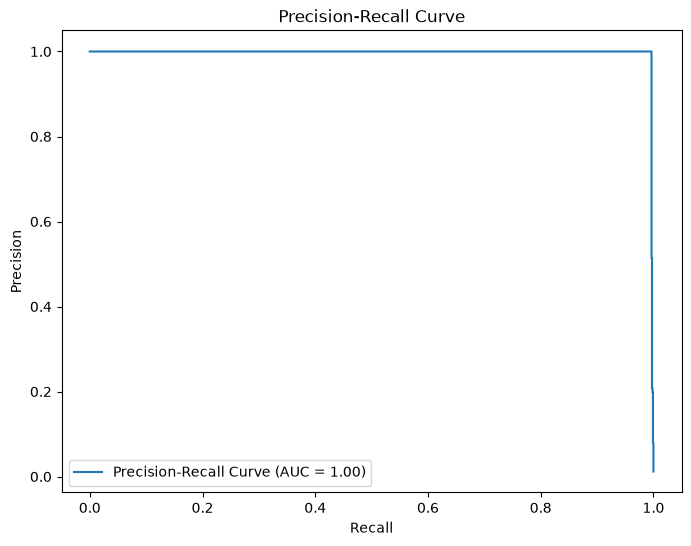

In [127]:
plt.figure(figsize=(8, 6))
plt.plot(xgb_recall,xgb_precision,label=f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

### Train a LGBMClassifier (LightGBM). LightGBM is generally much faster for 500k rows.

In [128]:
!pip install lightgbm

In [129]:
import lightgbm as lgb

In [130]:
train_data = lgb.Dataset(new_X_train, label=new_y_train)
valid_data = lgb.Dataset(X_test, label=y_test)

In [131]:
params={"objective":"binary",
        "metric":["auc","binary_logloss"],
        "boosting_type":"gbdt",
        "learning_rate":0.1,
        "num_leaves":31,
        "max_depth":-1,
        "feature_fraction":0.8,
        "bagging_fraction":0.8,
        "bagging_freq":5,
        "lambda_l1":0.1,
        "lambda_l2":0.2,
        "min_data_in_leaf":20,
         "verbose":-1
}

In [132]:
start_lgb_time = time.perf_counter()

In [133]:
model=lgb.train(params,
            train_data,
            num_boost_round=1000,
            valid_sets=[train_data,valid_data],
            valid_names=["train","valid"],
            callbacks=[lgb.early_stopping(50)])

lgb_train_time =  time.perf_counter() - start_lgb_time 


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[19]	train's auc: 0.999902	train's binary_logloss: 0.00206748	valid's auc: 0.999758	valid's binary_logloss: 0.00217911


In [134]:
lgb_train_time

1.999246000079438

In [135]:
y_pred_prob_lgb=model.predict(X_test,num_iteration=model.best_iteration)

In [136]:
y_pred_lgb=(y_pred_prob_lgb>0.5).astype(int)

In [137]:
y_pred_lgb[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [138]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, roc_auc_score

In [139]:
accuracy_lgb=accuracy_score(y_test,y_pred_lgb)
precision_lgb=precision_score(y_test,y_pred_lgb)
recall_lgb=recall_score(y_test,y_pred_lgb)
f1_lgb=f1_score(y_test,y_pred_lgb)
auc_lgb=roc_auc_score(y_test,y_pred_prob_lgb)

print(f'Accuracy:{accuracy_lgb}')
print(f'Precision:{precision_lgb}')
print(f'Recall:{recall_lgb}')
print(f'F1 Score:{f1_lgb}')
print(f'AUC:{auc_lgb}')

Accuracy:0.99996
Precision:1.0
Recall:0.9966471081307627
F1 Score:0.998320738874895
AUC:0.9997577215205058


### Compare the training time and inference latency (in milliseconds) between XGBoost and LightGBM. (Latency is critical for a payment gateway).

In [140]:
import time

In [141]:
print(f'Traing Time for XGB: {xgb_train_time}')
print(f'Traing Time for LGB: {lgb_train_time}')

Traing Time for XGB: 1.2558928998187184
Traing Time for LGB: 1.999246000079438


### Select your best performing gradient boosting model to move forward with.

##### NOTE
- Accuracy is better in the XGB model better than LGB(slightly differ).
- Letency is better in LGB as compare to XGB (approx. double)
- So I would choose LGB.

### Use RandomizedSearchCV to perform a hyperparameter tuning grid search.

In [142]:
from lightgbm import LGBMClassifier

In [143]:
from sklearn.model_selection import RandomizedSearchCV

In [144]:
lgbm = LGBMClassifier(objective='binary',random_state=42)

#### Tune max_depth (3, 5, 7), learning_rate (0.01, 0.1, 0.2), and n_estimators (100, 300, 500).

In [145]:
param_grid ={'max_depth': [3, 5, 7],
            'learning_rate': [0.01, 0.1, 0.2],
             'n_estimators': [100, 300, 500]
}

In [146]:
random_search = RandomizedSearchCV(estimator=lgbm,
                                  param_distributions=param_grid,
                                   n_iter=10,              
                                   scoring='roc_auc',      
                                   cv=5,
                                   random_state=42,
                                   n_jobs=-1)

In [147]:
random_search.fit(new_X_train, new_y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.01, 0.1, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 300, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the att

### Use scoring='f1_macro' or scoring='roc_auc' for the cross-validation metric.

In [175]:
y_pred_proba_randomCV = random_search.best_estimator_.predict_proba(X_test)[:, 1]

In [176]:
y_pred_proba_randomCV

array([8.25879834e-11, 2.17167996e-11, 8.60145936e-09, ...,
       8.11723820e-09, 4.30731054e-11, 1.37358055e-10], shape=(100000,))

In [177]:
print(f'Best Parameters : {random_search.best_params_}')

Best Parameters : {'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.1}


In [178]:
print(f'Best Cross-Validation AUC: {random_search.best_score_}')

Best Cross-Validation AUC: 0.9998217011333143


### Extract the best estimator from the search.

In [179]:
best_lgbm = random_search.best_estimator_

In [180]:
print(f' Best Model from the search : {best_lgbm}')

 Best Model from the search : LGBMClassifier(max_depth=7, n_estimators=500, objective='binary',
               random_state=42)


### Find the optimal probability threshold. Instead of using the default 0.5 cutoff, iterate through thresholds (0.1 to 0.9) to find the threshold that maximizes the F1-Score.

In [181]:
from sklearn.metrics import f1_score

In [182]:
type(f1_score)

function

In [183]:
y_prob_best_model = best_lgbm.predict_proba(X_test)[:, 1]

In [184]:
y_prob_best_model[:10]

array([8.25879834e-11, 2.17167996e-11, 8.60145936e-09, 6.52630978e-11,
       6.41991244e-11, 9.34251932e-10, 6.48489035e-11, 2.23182703e-09,
       6.24467958e-11, 3.79065926e-11])

In [185]:
threshold = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]

In [186]:
results = {
    "Threshold": [],
    "F1_Score": []}

In [187]:
for th in threshold:
    y_pred_new = ( y_prob_best_model >= th ).astype(int)
    score = f1_score(y_test, y_pred_new)
    results["Threshold"].append(th)
    results["F1_Score"].append(score)
    print(f'Threshold : {th} F1-Score : {score}')
    

Threshold : 0.1 F1-Score : 0.998320738874895
Threshold : 0.2 F1-Score : 0.998320738874895
Threshold : 0.3 F1-Score : 0.998320738874895
Threshold : 0.4 F1-Score : 0.998320738874895
Threshold : 0.5 F1-Score : 0.998320738874895
Threshold : 0.6 F1-Score : 0.998320738874895
Threshold : 0.7 F1-Score : 0.998320738874895
Threshold : 0.8 F1-Score : 0.998320738874895
Threshold : 0.9 F1-Score : 0.998320738874895


In [188]:
print(results)

{'Threshold': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], 'F1_Score': [0.998320738874895, 0.998320738874895, 0.998320738874895, 0.998320738874895, 0.998320738874895, 0.998320738874895, 0.998320738874895, 0.998320738874895, 0.998320738874895]}


In [189]:
f1_score_result = pd.DataFrame(results)

In [190]:
f1_score_result

,Threshold,F1_Score
0,0.1,0.998321
1,0.2,0.998321
2,0.3,0.998321
3,0.4,0.998321
4,0.5,0.998321
5,0.6,0.998321
6,0.7,0.998321
7,0.8,0.998321
8,0.9,0.998321


### Calculate the "Cost of Fraud": Assume a False Negative costs Nexlyra the full Transaction_Amount_USD. Assume a False Positive costs Nexlyra $5 in customer service friction.

In [191]:
X_test.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,-0.470893,1,1.678929,0,1.147047,1,1,2,-0.469208,0,0,1,0,0,-1.387447,0.0,2.0
1,0.248274,0,1.132120,0,0.235909,1,0,3,0.329846,0,0,0,0,1,0.932183,0.0,2.0
2,0.096413,4,1.611541,0,1.882825,1,2,5,0.040857,0,0,0,1,0,0.012348,0.0,2.0
3,-0.480664,3,-1.264987,0,-0.940858,1,0,2,-0.476002,0,0,0,0,1,0.972504,0.0,2.0
4,-0.387386,3,0.309979,1,1.260639,1,0,2,-0.364548,0,0,1,0,0,-0.286163,0.0,2.0


In [192]:
y_prediction_lgbm = best_lgbm.predict(X_test)

In [193]:
y_prediction_lgbm[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [194]:
customer = pd.DataFrame()

In [195]:
customer['Transaction_Amount_USD'] = X_test['Transaction_Amount_USD']
customer['Actual'] = y_test
customer['Predicted'] = y_prediction_lgbm

In [196]:
customer.head(5)

,Transaction_Amount_USD,Actual,Predicted
0,-0.470893,0,0
1,0.248274,0,0
2,0.096413,0,0
3,-0.480664,0,0
4,-0.387386,0,0


In [197]:
false_negative = customer[(customer['Actual'] == 1) & (customer['Predicted'] == 0)]
false_positive = customer[(customer['Actual'] == 0) & (customer['Predicted'] == 1)]

In [198]:
false_negative_cost = false_negative['Transaction_Amount_USD'].sum()

In [199]:
false_positive_cost = len(false_positive)*5

In [200]:
total = false_negative_cost + false_positive_cost

In [201]:
print(f'False Negative Cost: {false_negative_cost}')
print(f'False Positive Cost: {false_positive_cost}')
print(f'Total: {total}')

False Negative Cost: -0.6173134044227394
False Positive Cost: 0
Total: -0.6173134044227394


### Write a custom metric function to find the exact probability threshold that minimizes the total dollar cost to the business.

- Already model is performance is quite accurate, Hence No false positive on X_test dataset and Performing well on all threshold . So I would recommend to consider threshold at 0.5.

### Save the tuned model as tuned_lgb_model.pkl using joblib.

In [220]:
import joblib

In [221]:
joblib.dump(best_lgbm, "tuned_lgb_model.pkl")

['tuned_lgb_model.pkl']

### To-Do-03-08-26

In [209]:
!pip install shaptuned_lgb_model.pkl

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/554.9 kB ? eta -:--:--
   ---------------------------------------- 554.9/554.9 kB 3.8 MB/s  0:00:00
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/41.9 MB 6.7 MB/s eta 0:00:07
   -- ------------------------------------- 2.9/41.9 MB 7.6 MB/s eta 0:00:06
   ---- ----------------------------------- 5.0/41.9 MB 8.2 MB/s eta 0:00:05
   ------ --------------------------------- 6.3/41.9 MB 8.0 MB/s eta 0:00:05
   ------- -------------------------------- 7.3/41.9 MB 7.6 MB/s eta 0:00:05
   ------- -------------------------------- 8.1/41.9 MB 6.5 MB/s eta 0:00:06
   -------- ------------------------------- 8.7/41.9 MB 6.2 MB/s eta 0:00:06
   --------- ------------------------------ 9.4/41.9 MB 5.5 MB/s eta 0:00:06
   --------- -----------------------------

### 3. Import the shap library. Initialize a shap.TreeExplainer for your XGBoost/LightGBM model.

In [210]:
import shap

In [211]:
explainer = shap.TreeExplainer(best_lgbm) # Create a shap explainer

### 4. Calculate SHAP values for a random sample of 5,000 test set rows (calculating on all 100k test rows might crash your RAM).

In [212]:
shap_values = explainer.shap_values(X_test) # Calculating the shap value on X_test

C:\Users\ravis\anaconda3\envs\nexlyra\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [214]:
shap_values

array([[ 0.22100393, -0.01658303, -0.17793621, ...,  0.03414377,
         0.11271731,  0.09650256],
       [ 0.08795338,  0.01739704, -0.32357753, ..., -0.12937534,
        -0.15475187,  0.27910265],
       [ 0.40429011,  0.11508895,  0.1702843 , ...,  0.76050924,
        -0.20596818,  0.22352182],
       ...,
       [ 0.7220774 , -0.11205412, -0.31642077, ..., -0.64139965,
         0.86161935, -0.25319986],
       [-0.16881774, -0.02499909, -0.30419596, ..., -0.03529213,
         0.05307932,  0.04804404],
       [ 0.48328934,  0.06950978,  0.01865841, ..., -0.32103841,
         0.52237262, -0.21669547]], shape=(100000, 17))

### 5. Generate a shap.summary_plot (the classic dot plot) to show the global impact of features like Transaction_Velocity_1hr and IP_Country_Match on the model's output. Save as shap_summary.png.

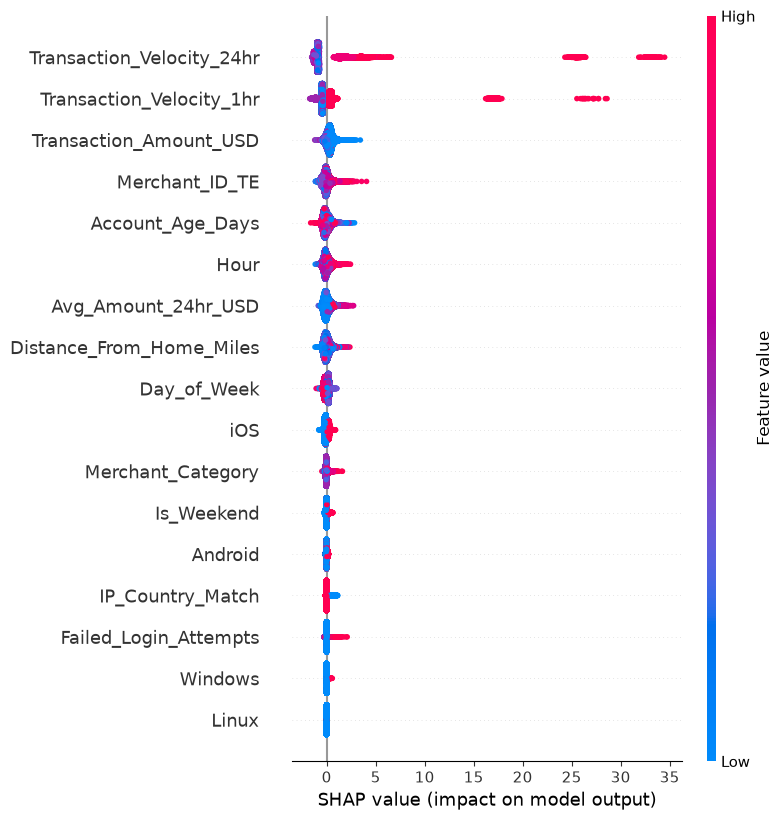

<Figure size 640x480 with 0 Axes>

In [246]:
shap.summary_plot(shap_values, X_test) # Summary plot of shap value and its impact on X_test.
plt.savefig("shap_summary.png")

#### Note:-
- Impact of SHAP value is correlated to feature that we have seen on heatmap.
- We are using the unsmoted data for traing LGB model because it was build according to instruction so Classes might still imbalance.
- But still we are getting good correlation of SHAP value and its impact on features.

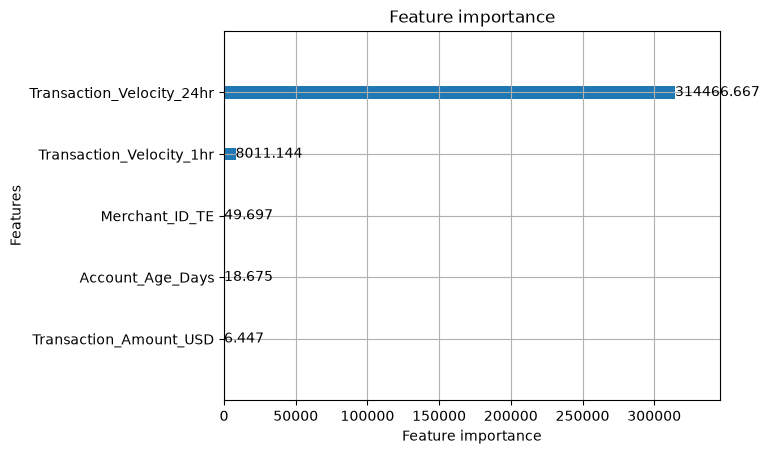

In [218]:
lgb.plot_importance(model,max_num_features=17,importance_type='gain') ## Feature importance by using plotting that expain the correlation with its importance.
plt.show()

### Note:-
- Still we are getting the same respose as we can see the Transaction_Velocity_24hr and Transaction_Velocity_1hr are highly correlated.

### 1. Model Explainability (SHAP) & Error Analysis

In [219]:
y_prob_best_model = best_lgbm.predict_proba(X_test)[:, 1]

In [220]:
f1_score_result

,Threshold,F1_Score
0,0.1,0.998321
1,0.2,0.998321
2,0.3,0.998321
3,0.4,0.998321
4,0.5,0.998321
5,0.6,0.998321
6,0.7,0.998321
7,0.8,0.998321
8,0.9,0.998321


In [221]:
y_pred_best_model = (y_prob_best_model>= 0.5).astype(int) # Best threshold I considered as 0.5 because it was perfoming well on all threshold

In [222]:
y_pred_best_model

array([0, 0, 0, ..., 0, 0, 0], shape=(100000,))

##### Error Analysis

In [230]:
from sklearn.metrics import confusion_matrix
matrix = confusion_matrix(y_test,y_pred_best_model)

In [231]:
print(matrix)

[[98807     0]
 [    4  1189]]


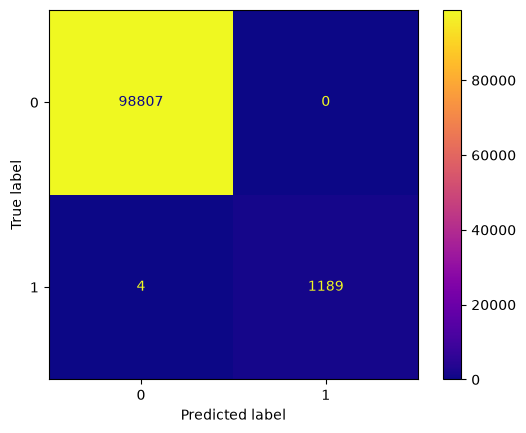

In [236]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best_model,cmap='plasma')
plt.show()

In [237]:
dataset = pd.DataFrame()
dataset['Actual'] = y_test
dataset['prediction'] = y_pred_best_model

In [238]:
dataset.head(5)

,Actual,prediction
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


In [244]:
True_positive = dataset[(dataset['Actual'] == 1) & (dataset['prediction'] == 1)].shape[0]
True_negative = dataset[(dataset['Actual'] == 0) & (dataset['prediction'] == 0)].shape[0]
false_positive = dataset[(dataset['Actual'] == 0) & (dataset['prediction'] == 1)].shape[0]
false_negative = dataset[(dataset['Actual'] == 1) & (dataset['prediction'] == 0)].shape[0]

In [245]:
print(f'True Postive: {True_positive}')
print(f'True Negative: {True_negative}')
print(f'False Postive: {false_positive}')
print(f'False Negative: {false_negative}')

True Postive: 1189
True Negative: 98807
False Postive: 0
False Negative: 4


### 2. Load your tuned model. You need to explain why the AI is declining transactions to the compliance team.

In [248]:
import joblib

In [250]:
model_name = "tuned_lgb_model.pkl"
tuned_lgb_model = joblib.load(model_name)

In [ ]:
### Need to explain later

### 6. Generate a shap.dependence_plot for Transaction_Amount_USD. Does the risk scale linearly with the amount?

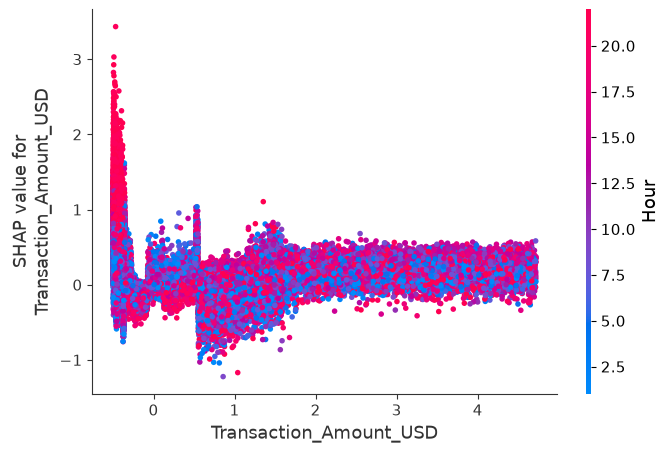

In [251]:
shap.dependence_plot("Transaction_Amount_USD",shap_values,X_test)
plt.show()

### Insight:
-  Transaction_Amount_USD < 0 have more +ve SHAP value and Hours is more than 10.
- Transaction_Amount_USD  > 0 have SHAP value mostly between 0 and 1 and Hours is less than 10.
- It follows intially decreasing then became almost constant. Hence it the risk sclae is not linear.

### 7. Perform Error Analysis: Isolate the False Positives (legitimate transactions predicted as fraud).

In [254]:
false_positive_df = X_test[(dataset['Actual'] == 0) & (dataset['prediction'] == 1)]

In [255]:
false_positive_df

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week


Note:-
- We don't have False Positive dataset to analyze because the model is predicting 0 false positive.

### 8. Analyze the False Positives. Do they share a specific Merchant_Category (e.g., Travel is often falsely flagged due to foreign IPs)?

In [256]:
false_positive_df

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week


### Note:-
- We don't have False Positive dataset to analyze because the model is predicting 0 false positive.

### 9. Isolate the False Negatives (fraud that slipped through).

In [257]:
false_negative_df = X_test[(dataset['Actual'] == 1) & (dataset['prediction'] == 0)]

In [258]:
false_negative_df

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
8697,-0.488753,3,1.153299,0,-0.860006,1,2,5,-0.483132,0,1,0,0,0,-0.659239,9.0,1.0
16260,-0.481981,2,-1.426719,1,-0.252395,1,2,6,-0.479911,1,0,0,0,1,0.249087,22.0,6.0
42545,-0.459505,2,-0.387011,0,-0.584451,1,2,6,-0.450173,1,0,0,0,1,0.154146,3.0,5.0
43630,0.812926,4,-0.075098,0,-0.783620,0,2,6,1.022504,1,1,0,0,0,-0.993270,22.0,5.0


In [259]:
false_negative_pred_df = dataset[(dataset['Actual'] == 1) & (dataset['prediction'] == 0)]

In [260]:
false_negative_pred_df

,Actual,prediction
8697,1,0
16260,1,0
42545,1,0
43630,1,0


In [264]:
false_negative_complete = pd.concat([false_negative_df,false_negative_pred_df], axis = 1)

In [280]:
false_negative_complete

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week,Actual,prediction
8697,-0.488753,3,1.153299,0,-0.860006,1,2,5,-0.483132,0,1,0,0,0,-0.659239,9.0,1.0,1,0
16260,-0.481981,2,-1.426719,1,-0.252395,1,2,6,-0.479911,1,0,0,0,1,0.249087,22.0,6.0,1,0
42545,-0.459505,2,-0.387011,0,-0.584451,1,2,6,-0.450173,1,0,0,0,1,0.154146,3.0,5.0,1,0
43630,0.812926,4,-0.075098,0,-0.783620,0,2,6,1.022504,1,1,0,0,0,-0.993270,22.0,5.0,1,0


In [266]:
false_negative_complete.to_csv("false_negatives.csv", index=False)

### 10. Pick one specific False Negative transaction and generate a shap.force_plot or shap.waterfall_plot to explain exactly why the model missed it.

In [267]:
expected_value = explainer.expected_value

In [270]:
row_index = X_test.index.get_loc(false_negative_df.index[0])

In [271]:
row_index

8697

In [278]:
shap.initjs()

In [279]:
shap.force_plot(expected_value,shap_values[row_index],X_test.iloc[row_index])

#### NOTE:-
- All negative SHAP value move towards -ve base value -18.24.
- More Red features increase the model output f(x) toward fraud.
- less Blue featues increase the model output f(x) toward non-fraud.
- But commulative sum of red and blue feature increase the model output f(x)= -18.24 towards 0 .
- Hence model predict 0 instead of 1.

### 11. Write a short Python script explain_prediction.py that takes a single transaction row and outputs a human-readable text explanation based on SHAP values (e.g., "Flagged due to: IP Mismatch (40% im

In [281]:
new_test = X_test[:5]

In [282]:
new_test

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,-0.470893,1,1.678929,0,1.147047,1,1,2,-0.469208,0,0,1,0,0,-1.387447,0.0,2.0
1,0.248274,0,1.132120,0,0.235909,1,0,3,0.329846,0,0,0,0,1,0.932183,0.0,2.0
2,0.096413,4,1.611541,0,1.882825,1,2,5,0.040857,0,0,0,1,0,0.012348,0.0,2.0
3,-0.480664,3,-1.264987,0,-0.940858,1,0,2,-0.476002,0,0,0,0,1,0.972504,0.0,2.0
4,-0.387386,3,0.309979,1,1.260639,1,0,2,-0.364548,0,0,1,0,0,-0.286163,0.0,2.0


In [283]:
new_test.to_csv("test.csv", index=False)

- "python explain_prediction.py --csv test.csv" run in the terminal